# Figure 6 — publication plotting

This notebook reads only the validated tables produced by the analysis
notebook. It exports four analytical panels and the assembled Figure 6 in PNG,
SVG/PDF panel files, and TIFF. All estimates are plotted on ratio scales with a
null reference at 1 and archived 95% confidence intervals.


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
).resolve()
REFERENCE_DIR = PROJECT_ROOT / "data" / "reference" / "figure_6"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "figure_6_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_6_clean"
for directory in [REFERENCE_DIR, OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from PIL import Image as PILImage, ImageChops

BLUE = "#087EBD"
ORANGE = "#E36A00"
TEAL = "#00A67E"
PURPLE = "#8053A6"
DARK = "#202832"
MID = "#667386"
GRID = "#DDE3E9"
BAND = "#F2F5F8"
WHITE = "#FFFFFF"

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.labelcolor": DARK, "text.color": DARK,
    "xtick.color": "#4E5968", "ytick.color": DARK,
    "axes.linewidth": 1.1, "figure.facecolor": WHITE,
    "axes.facecolor": WHITE, "savefig.facecolor": WHITE,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

def p_text(value):
    return f"{value:.1e}" if value < 0.001 else f"{value:.3f}"

def panel_letter(fig, letter):
    fig.text(0.025, 0.965, letter, fontsize=34, fontweight="bold",
             color=DARK, ha="left", va="top")

def clean_axes(ax):
    ax.grid(axis="x", color=GRID, linewidth=1)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#8B96A3")
    ax.spines["bottom"].set_color("#8B96A3")

def ratio_ticks(ax, ticks):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())

def save_panel(fig, stem):
    paths = {}
    for suffix in ["png", "svg", "pdf"]:
        path = FIGURE_DIR / f"{stem}.{suffix}"
        fig.savefig(path, dpi=400, bbox_inches="tight", pad_inches=0.12)
        paths[suffix] = path
    return paths

def read_panel(stem):
    path = OUTPUT_DIR / stem
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 01_Figure6_Analysis.ipynb first."
        )
    return pd.read_csv(path)

panel_a = read_panel("panel_a_2d_subgroups.csv")
panel_b = read_panel("panel_b_formal_interactions.csv")
panel_c = read_panel("panel_c_context_interactions.csv")
panel_d = read_panel("panel_d_checkmate025.csv")

Project root: /scratch/ar58064/mitoxy


## Shared forest-plot helper


In [2]:
def forest_panel(
    data, label_col, estimate_col, color, letter, xlabel, stem,
    xlim, ticks, p_col="p_value", fdr_col=None, n_col=None,
    point_size=11, left=0.34, stat_x=0.985,
):
    data = data.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(10.6, 5.9))

    for i in range(len(data)):
        if i % 2 == 1:
            ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)

    for i, row in data.iterrows():
        estimate = row[estimate_col]
        ax.errorbar(
            estimate, i,
            xerr=[[estimate - row["ci_low"]], [row["ci_high"] - estimate]],
            fmt="o", color=color, ecolor=color, markersize=point_size,
            elinewidth=3.0, capsize=7, capthick=2,
            markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3,
        )
        first = (
            rf"HR = {estimate:.2f} ({row['ci_low']:.2f}–{row['ci_high']:.2f})"
            if estimate_col == "hr" else
            rf"Effect = {estimate:.2f} ({row['ci_low']:.2f}–{row['ci_high']:.2f})"
        )
        second = rf"$P$ = {p_text(row[p_col])}"
        if fdr_col is not None:
            second += rf"  •  FDR = {row[fdr_col]:.3f}"
        ax.text(
            stat_x, i, first + "\n" + second,
            transform=ax.get_yaxis_transform(), ha="right", va="center",
            fontsize=11.6, fontweight="bold", color=color,
            bbox={
                "boxstyle": "round,pad=0.30,rounding_size=0.13",
                "facecolor": (1, 1, 1, 0.84), "edgecolor": color,
                "linewidth": 1.2,
            },
        )

    labels = []
    for _, row in data.iterrows():
        label = str(row[label_col])
        if n_col is not None:
            label += "\n" + rf"$n$ = {int(row[n_col])}"
        labels.append(label)
    ax.set_yticks(y, labels, fontsize=12.7)
    ax.axvline(1, color="#8B96A3", linestyle="--", linewidth=1.5)
    ax.set_xlim(*xlim)
    ax.set_ylim(-0.55, len(data)-0.45)
    ratio_ticks(ax, ticks)
    ax.set_xlabel(xlabel, fontsize=16, labelpad=13)
    ax.tick_params(axis="y", length=0, pad=12)
    clean_axes(ax)
    panel_letter(fig, letter)
    fig.subplots_adjust(left=left, right=0.97, top=0.90, bottom=0.19)
    paths = save_panel(fig, stem)
    plt.show()
    return paths

## Panel A — two-dimensional subgroup treatment effects


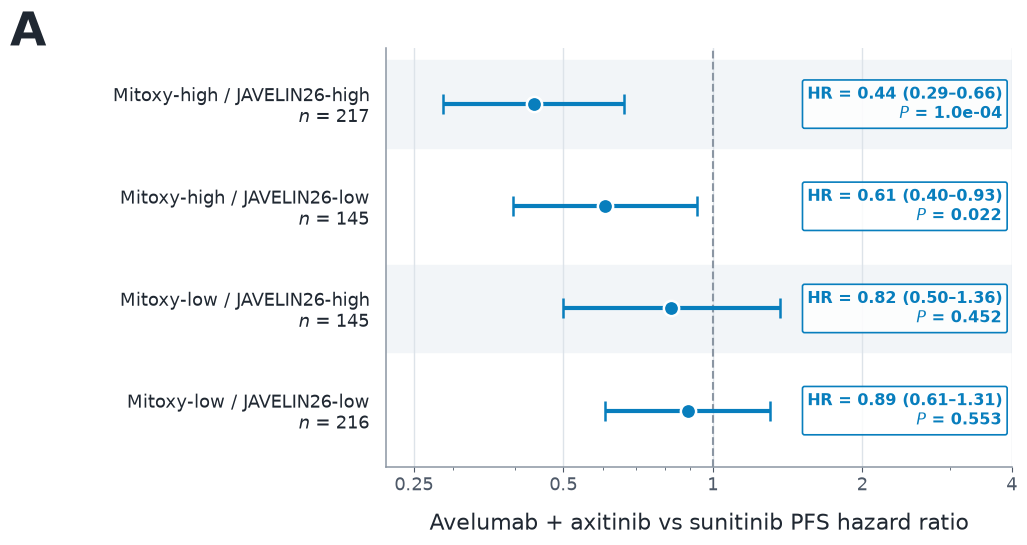

In [3]:
panel_a_paths = forest_panel(
    panel_a, "subgroup", "hr", BLUE, "A",
    "Avelumab + axitinib vs sunitinib PFS hazard ratio",
    "figure_6a_2d_subgroups",
    xlim=(0.22, 4.0), ticks=[0.25, 0.5, 1, 2, 4], n_col="n", left=0.38,
)


## Panel B — formal continuous interactions


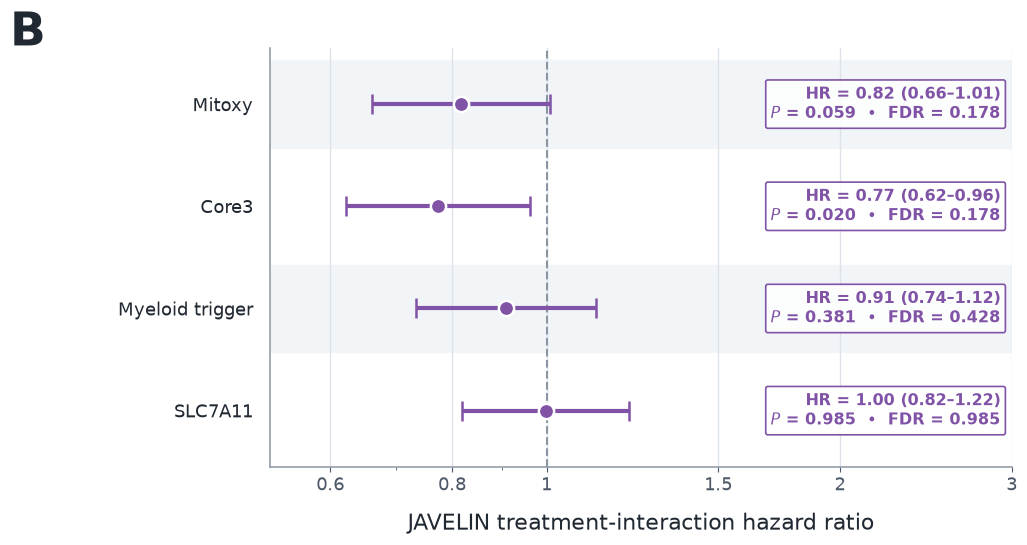

In [4]:
panel_b_paths = forest_panel(
    panel_b, "score", "hr", PURPLE, "B",
    "JAVELIN treatment-interaction hazard ratio",
    "figure_6b_formal_interactions",
    xlim=(0.52, 3.0), ticks=[0.6, 0.8, 1, 1.5, 2, 3],
    fdr_col="fdr", n_col=None, left=0.27,
)


## Panel C — context-stratified interactions


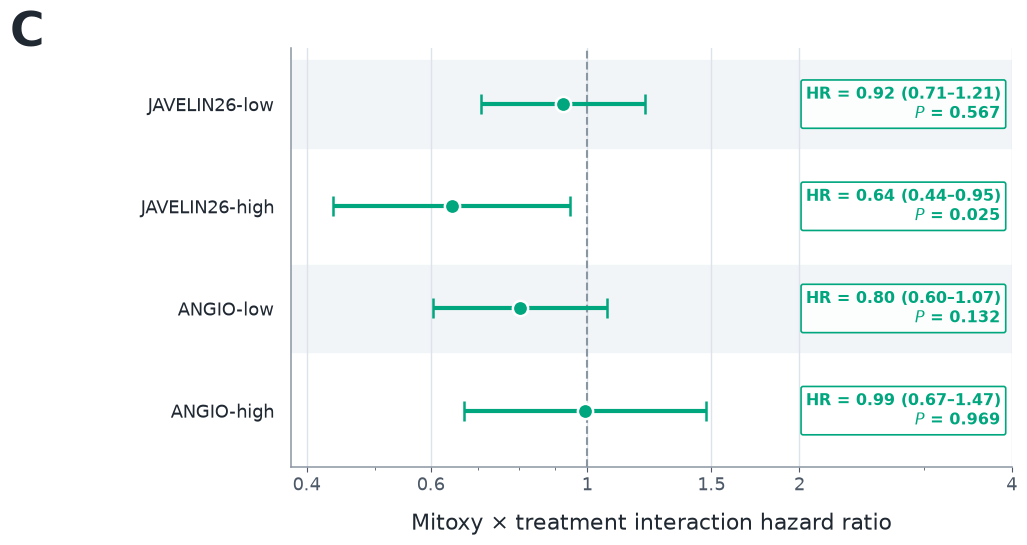

In [5]:
panel_c_paths = forest_panel(
    panel_c, "context_stratum", "hr", TEAL, "C",
    "Mitoxy × treatment interaction hazard ratio",
    "figure_6c_context_interactions",
    xlim=(0.38, 4.0), ticks=[0.4, 0.6, 1, 1.5, 2, 4],
    n_col=None, left=0.29,
)


## Panel D — CheckMate 025 boundary test


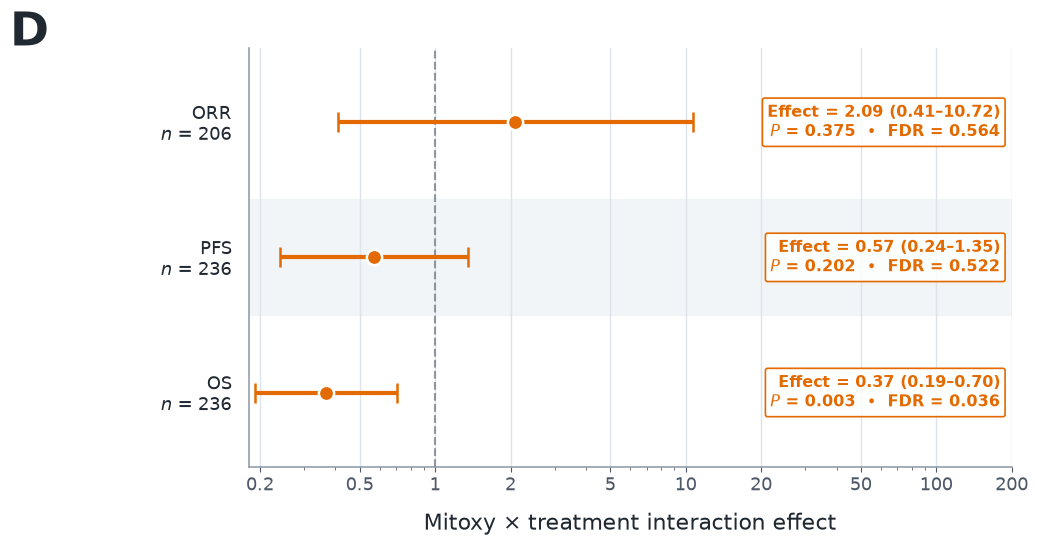

In [6]:
panel_d_paths = forest_panel(
    panel_d, "outcome", "effect", ORANGE, "D",
    "Mitoxy × treatment interaction effect",
    "figure_6d_checkmate025",
    xlim=(0.18, 200), ticks=[0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200],
    fdr_col="fdr", n_col="n", left=0.25,
)


## Assemble Figure 6


Saved:
/scratch/ar58064/mitoxy/figures/figure_6_clean/Figure_6_complete.png
/scratch/ar58064/mitoxy/figures/figure_6_clean/Figure_6_complete.tiff


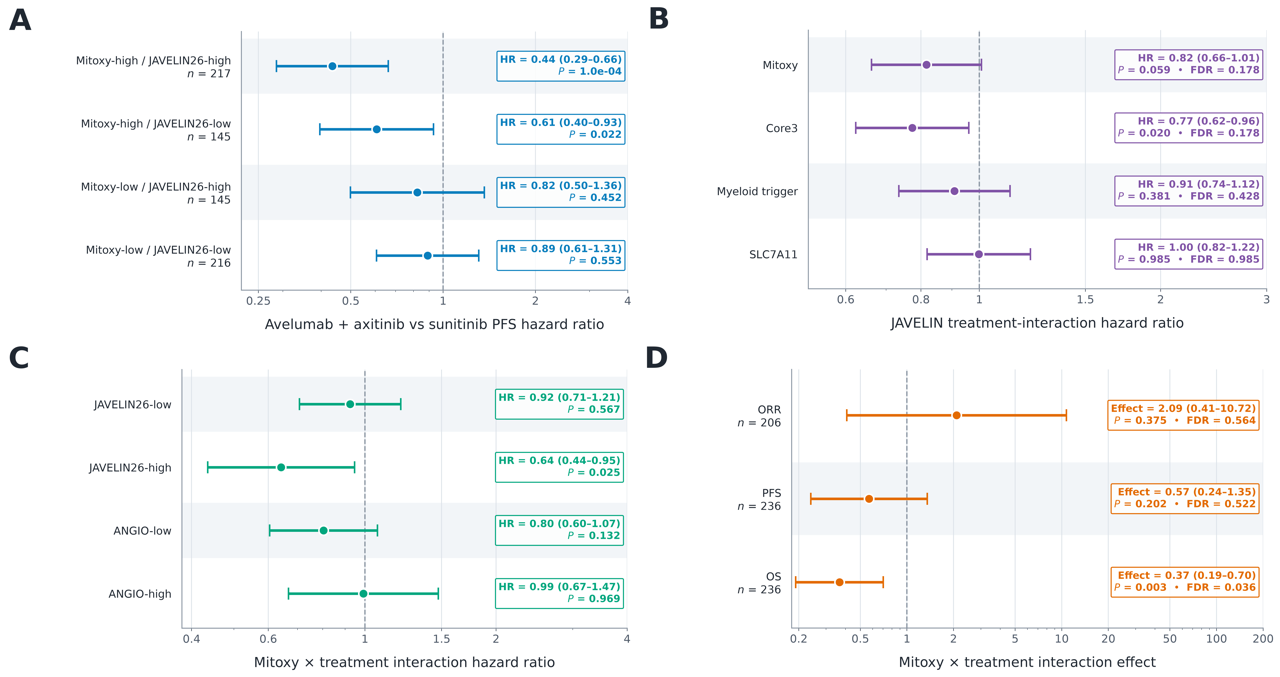

In [7]:
panel_paths = {
    "A": panel_a_paths["png"], "B": panel_b_paths["png"],
    "C": panel_c_paths["png"], "D": panel_d_paths["png"],
}

def crop_white(path, threshold=248):
    image = PILImage.open(path).convert("RGB")
    background = PILImage.new("RGB", image.size, (255, 255, 255))
    diff = ImageChops.difference(image, background).convert("L")
    diff = diff.point(lambda p: 255 if p > (255-threshold) else 0)
    bbox = diff.getbbox()
    return image.crop(bbox) if bbox else image

cropped = {key: crop_white(path) for key, path in panel_paths.items()}
cell_w = max(image.width for image in cropped.values())
cell_h = max(image.height for image in cropped.values())
gap_x, gap_y = 90, 100
margin = 45
canvas = PILImage.new(
    "RGB", (2*cell_w + gap_x + 2*margin, 2*cell_h + gap_y + 2*margin),
    "white",
)
positions = {
    "A": (margin, margin),
    "B": (margin + cell_w + gap_x, margin),
    "C": (margin, margin + cell_h + gap_y),
    "D": (margin + cell_w + gap_x, margin + cell_h + gap_y),
}
for key, image in cropped.items():
    x, y = positions[key]
    x += (cell_w - image.width)//2
    y += (cell_h - image.height)//2
    canvas.paste(image, (x, y))

complete_png = FIGURE_DIR / "Figure_6_complete.png"
complete_tiff = FIGURE_DIR / "Figure_6_complete.tiff"
canvas.save(complete_png, dpi=(400, 400))
canvas.save(complete_tiff, compression="tiff_lzw", dpi=(400, 400))

print("Saved:")
print(complete_png)
print(complete_tiff)
display(canvas.resize((1280, round(1280 * canvas.height / canvas.width))))
